In [29]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("loan_approved.csv")

In [3]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [33]:
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [34]:
df['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [35]:
df.loc[df['Gender'].isnull(),'Gender']="Male"# we have inputed the null values

In [36]:
df.Gender.isnull().sum()

np.int64(0)

In [ ]:
df['Credit_History'].value_counts().mode()

In [ ]:
df.loc[df['Credit_History'].isnull(),'Credit_History']=0.0

In [ ]:
df['Credit_History'].value_counts()

In [ ]:
df.Credit_History.isnull().sum()

In [ ]:
df.loc[df['LoanAmount'].isnull(),'LoanAmount']=df['LoanAmount'].median()

In [ ]:
df.loc[df['Married'].isnull(),'Married']='yes'

In [ ]:
df.Married.isnull().sum()

In [ ]:
df.loc[df['Self_Employed'].isnull(),'Self_Employed']='No'

In [ ]:
df.Self_Employed.isnull().sum()

In [41]:
df.loc[df['Loan_Amount_Term'].isnull(),'Loan_Amount_Term']=360.0

In [ ]:
df.loc[df['Dependents'].isnull(),'Dependents']='0'

In [ ]:
df.isnull().sum()

In [ ]:
df

### VISUALIZING THE OUTLIERS

<Axes: xlabel='LoanAmount'>

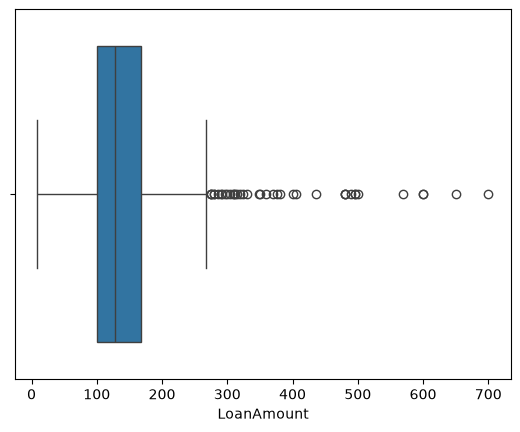

In [48]:
sns.boxplot(x=df.LoanAmount,orient='h')

In [49]:
from scipy.stats.mstats import winsorize

#specify the percentage of data to be trimed from both te ends
trim_percentage=0.08

#winsorize the specified column
df['ApplicantIncome']=winsorize(df['ApplicantIncome'],limits=trim_percentage)

<Axes: xlabel='ApplicantIncome'>

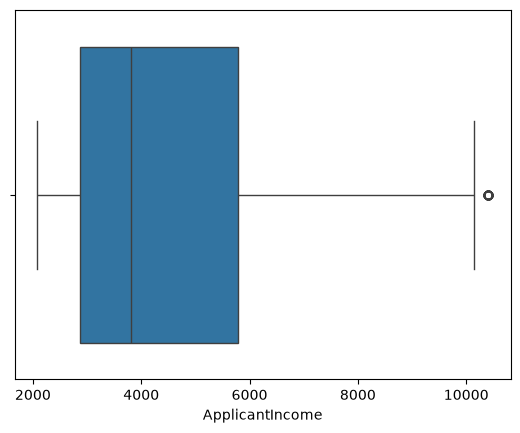

In [50]:
sns.boxplot(x=df.ApplicantIncome,orient='h')

### USING IQR METHOD TO HANDLE THE OUTLIERS

In [ ]:
#calculate quartiles
Q1=df['LoanAmount'].quantile(0.25)
Q3=df['LoanAmount'].quantile(0.75)

In [ ]:
#calculate IQR
IQR=Q3-Q1
IQR

In [ ]:
#define lower and upper bounds
lower_bound=Q1 - 1.5 * IQR
upper_bound=Q3 + 1.5 * IQR

In [ ]:
print(lower_bound)
print(upper_bound)

In [ ]:
#removve outliers
df=df[(df['LoanAmount'] >=lower_bound) & (df['LoanAmount'] <=upper_bound)]

<Axes: xlabel='LoanAmount'>

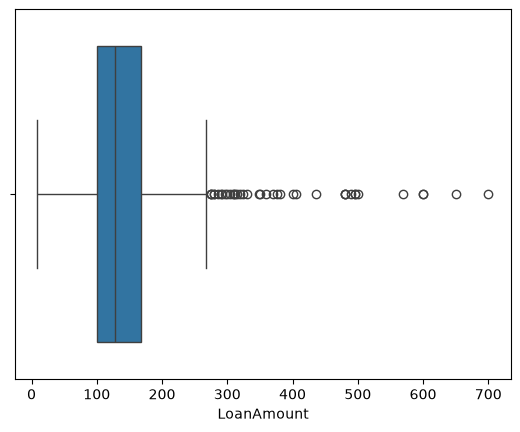

In [51]:
sns.boxplot(x=df.LoanAmount,orient='h')

## ENCODING TYPES

### ONE HOT ENCODING

In [53]:
df_encoded=pd.get_dummies(df,columns=['Married'],prefix='Married')

In [54]:
df_encoded.columns

Index(['Loan_ID', 'Gender', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'Married_No', 'Married_Yes'],
      dtype='str')

### LABEL ENCODING

In [55]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

#fit and transform the 'matchType' column to obtain label-encoded values
df['Married']=encoder.fit_transform(df['Married'])

#display results
print(df[['Married']])

     Married
0          0
1          1
2          1
3          1
4          0
..       ...
609        0
610        1
611        1
612        1
613        0

[614 rows x 1 columns]


In [56]:
df_encoded=pd.get_dummies(df,columns=['Loan_Status (Approved)'],prefix='Loan_Status (Approved)')

In [57]:
df_encoded.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)_N', 'Loan_Status (Approved)_Y'],
      dtype='str')

In [58]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

#fit and transform the 'matchType' column to obtain label-encoded values
df['Loan_Status (Approved)']=encoder.fit_transform(df['Loan_Status (Approved)'])

#display results
print(df[['Loan_Status (Approved)']])

     Loan_Status (Approved)
0                         1
1                         0
2                         1
3                         1
4                         1
..                      ...
609                       1
610                       1
611                       1
612                       1
613                       0

[614 rows x 1 columns]


### ORDINAL ENCODING

In [59]:
df.Education.value_counts()

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

In [60]:
Education_enc=OrdinalEncoder(categories=[['Graduate','Not Graduate']])

In [61]:
df['Education']=encoder.fit_transform(df['Education'])

In [62]:
print(df[['Education']])

     Education
0            0
1            0
2            0
3            1
4            0
..         ...
609          0
610          0
611          0
612          0
613          0

[614 rows x 1 columns]


In [63]:
df.Education.value_counts()

Education
0    480
1    134
Name: count, dtype: int64

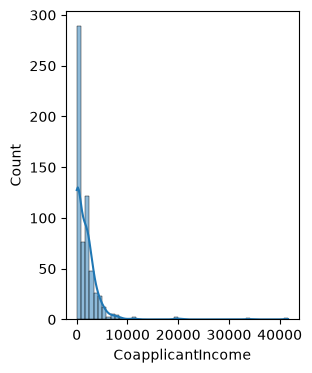

In [64]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'],kde=True)
plt.show()

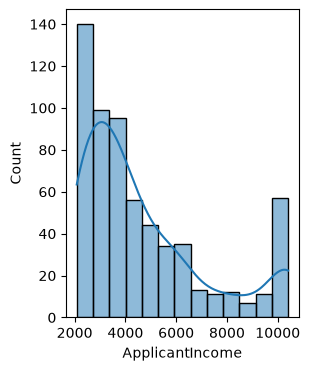

In [65]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'],kde=True)
plt.show()

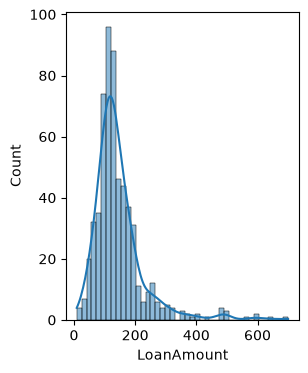

In [66]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'],kde=True)
plt.show()

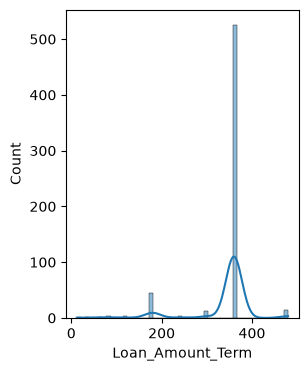

In [67]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['Loan_Amount_Term'],kde=True)
plt.show()

### LOG TRANSFORMATION

In [68]:
df['CoapplicantIncome']=np.log(df['CoapplicantIncome'])

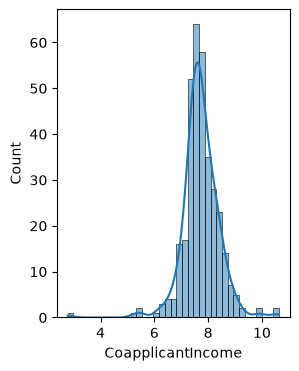

In [69]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'],kde=True)
plt.show()

### EXPONENTIAL TRANSFORMATION

In [70]:
df['ApplicantIncome_exponential']=df.ApplicantIncome**(1/1.2)

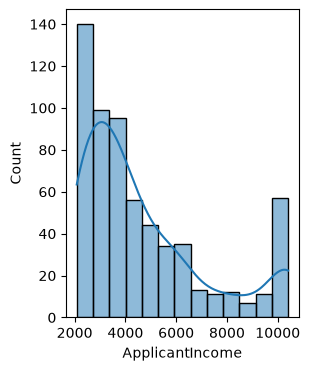

In [71]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'],kde=True)
plt.show()

### SQUARE ROOT TRANSFORMATION

In [72]:
df['LoanAmount']=df.LoanAmount**(1/2)

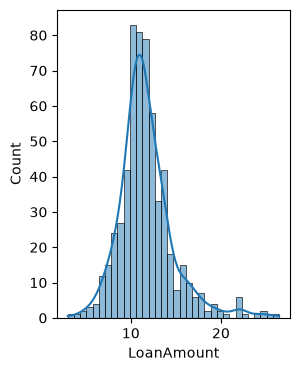

In [73]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'],kde=True)
plt.show()

### BOXCOX TRANFORMATION

In [74]:
from scipy.stats import boxcox
transformed_data, lambda_value= boxcox(df['Loan_Amount_Term'])

In [75]:
#print("Tranformed data:",transformed_data)

In [76]:
print("Lambda value:",lambda_value)

Lambda value: 3.01792025163975


### SCALING TECHNIQUES

#### Using standard scalar  

In [4]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='str')

In [5]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
ApplicantIncome_scaled=scaler.fit_transform(df[['ApplicantIncome']])

In [6]:
ApplicantIncome_scaled

array([[ 7.29908229e-02],
       [-1.34411954e-01],
       [-3.93747337e-01],
       [-4.62062470e-01],
       [ 9.77284368e-02],
       [ 2.21831139e-03],
       [-5.03018784e-01],
       [-3.87849628e-01],
       [-2.28939128e-01],
       [ 1.21845703e+00],
       [-3.60982286e-01],
       [-4.75659966e-01],
       [-3.81788093e-01],
       [-5.81654908e-01],
       [-6.72414101e-01],
       [-7.42880841e-02],
       [-2.96107483e-01],
       [-3.10196456e-01],
       [-8.46090753e-02],
       [-4.59277440e-01],
       [ 3.69678365e-01],
       [ 9.03563002e-02],
       [-4.59277440e-01],
       [-3.33951118e-01],
       [-2.76284627e-01],
       [ 6.80946355e-01],
       [-4.26676214e-01],
       [-1.92897571e-01],
       [-6.48987089e-01],
       [-2.70878394e-01],
       [-2.02727086e-01],
       [-3.66388519e-01],
       [-1.16555001e-01],
       [-3.11834708e-01],
       [ 1.16259261e+00],
       [-5.12520649e-01],
       [-5.85750540e-01],
       [-2.84475890e-01],
       [-2.0

#### MINMAX SCALING

In [7]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
ApplicantIncome_scaled2=scaler.fit_transform(df[['ApplicantIncome']])

#### ROBUST SCALING

In [8]:
from sklearn.preprocessing import RobustScaler
scaler=RobustScaler()
ApplicantIncome_scaled3=scaler.fit_transform(df[['ApplicantIncome']])